# SAPHIR pre-processing, DCC reference flag and Gaussian Mixture clustering (Megha-Tropiques, 1 Jan 2014 granule)

Main working notebook. Steps: read SAPHIR L1A HDF5 -> apply scale/fill values -> build a dictionary of lat/lon, incidence angle, time and brightness temperatures (TB1-TB6) -> load a gridded pickle for one orbit -> compute the reference DCC flag with `grid_func.dcc_flag` -> fit a 2-component Gaussian Mixture Model separately for incidence angles 0-25 and 26-52 degrees -> compare with the reference flag via row-normalised confusion matrices (final results near the end).

Requires `src/grid_func.py` (gridding + `dcc_flag`) on the Python path and MOSDAC data (see `data/README.md`). Paths are the Colab paths from the original run; edit them for your machine.


In [ ]:
from google.colab import drive

In [ ]:
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
!unzip gdrive/My\Drive/DATA_MT/Jan2014.zip

Archive:  gdrive/MyDrive/DATA_MT/Jan2014.zip
  inflating: Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_00_35_51_2014_01_01_02_28_04_11469_11470_119_24_25_BL1_01.h5  
  inflating: Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_04_10_58_2014_01_01_06_06_27_11472_11473_119_27_28_BL2_00.h5  
  inflating: Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_06_01_55_2014_01_01_07_56_14_11473_11474_119_28_29_BL2_00.h5  
  inflating: Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_07_51_45_2014_01_01_09_45_40_11474_11475_119_29_30_BL1_00.h5  
  inflating: Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_09_40_55_2014_01_01_11_34_59_11475_11476_119_30_31_BL3_00.h5  
  inflating: Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_11_30_14_2014_01_01_13_24_55_11476_11477_119_31_32_BL1_00.h5  
  inflating: Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_13_19_13_2014_01_01_15_16_17_11477_11478_119_32_33_BL1_00.h5  
  inflating: Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_15_11_42_2014_01_01_16_26_53_11478

In [ ]:
def file_process(folder):


In [ ]:
flsp="/content/Jan2014/MT1SAPSL1A__1.06_000_9_16_I_2014_01_01_06_01_55_2014_01_01_07_56_14_11473_11474_119_28_29_BL2_00.h5"

In [ ]:
F1=h5.File(flsp,'r')

In [ ]:
F1["ScienceData"].keys()


<KeysViewHDF5 ['IncidenceAngle_Samples', 'Latitude_Nadir', 'Latitude_Samples', 'Longitude_Nadir', 'Longitude_Samples', 'QF_Samples_S1', 'QF_Samples_S2', 'QF_Samples_S3', 'QF_Samples_S4', 'QF_Samples_S5', 'QF_Samples_S6', 'SAPHIR_QF_scan', 'Scan_FirstSampleAcqTime', 'Scan_Gain', 'Scan_HotLoadTemperature', 'Scan_Number', 'Scan_Offset', 'TB_Samples_S1', 'TB_Samples_S2', 'TB_Samples_S3', 'TB_Samples_S4', 'TB_Samples_S5', 'TB_Samples_S6']>

In [ ]:
noval = -9999.0

**Declaring Saphir Dictionary for storing necessary attributes**

In [ ]:
dctsp={}

'**Latitude_Samples**'


In [ ]:
meta = (F1["ScienceData/Latitude_Samples"]).attrs
sc = meta["scale_factor"]
fv = meta["_FillValue"]
fillval = float(fv.decode())
scale = float(sc.decode())
bb= (F1["ScienceData/Latitude_Samples"][:])
lat1A=np.ones(np.shape(bb))*noval
lat1A[bb!=fillval]=(bb[bb!=fillval]*scale) - 40
del bb
#lat1A=((F1["ScienceData/Latitude_Samples"])[:] * scale) - 40
dctsp['latsp']=lat1A


**'Longitude_Samples'**

In [ ]:
meta = (F1["ScienceData/Longitude_Samples"]).attrs
sc = meta["scale_factor"]
fv = meta["_FillValue"]
fillval = float(fv.decode())
scale = float(sc.decode())
bb= (F1["ScienceData/Longitude_Samples"][:])
long1A=np.ones(np.shape(bb))*noval
long1A[bb!=fillval]=(bb[bb!=fillval]*scale)
del bb
#long1A=(F1["ScienceData/Longitude_Samples"][:]) * scale
long1A[long1A>180.0]=long1A[long1A>180.0]-360.0
dctsp['lonsp']=long1A

**'IncidenceAngle_Samples'**

In [ ]:
meta = (F1["ScienceData/IncidenceAngle_Samples"]).attrs
sc = meta["scale_factor"]
scale = float(sc.decode())
fv = meta["_FillValue"]
fillval = float(fv.decode())
bb= (F1["ScienceData/IncidenceAngle_Samples"][:])
data1A=np.ones(np.shape(bb))*noval
data1A[bb!=fillval]=(bb[bb!=fillval]*scale)
del bb
#data1A=(F1["ScienceData/IncidenceAngle_Samples"][:])* scale
dctsp['stznsp']=data1A


**'Time'**

In [ ]:
time1A = np.squeeze((F1['ScienceData/Scan_FirstSampleAcqTime'][:]))

outtim=grid_func.gen_time_array(time1A,np.shape(lat1A)[0],np.shape(lat1A)[1])

dctsp['timsp']=outtim


**'TB Samples from 1 to 6'**

In [ ]:
meta = (F1["ScienceData/TB_Samples_S1"]).attrs
sc = meta["scale_factor"]
scale = float(sc.decode())
fv = meta["_FillValue"]
fillval = float(fv.decode())
bb= (F1["ScienceData/TB_Samples_S1"][:])
TB1=np.ones(np.shape(bb))*noval
TB1[bb!=fillval]=(bb[bb!=fillval]*scale)
del bb
#TB1 = (F1["ScienceData/TB_Samples_S1"][:]) * scale
dctsp['bt1sp']=TB1

meta = (F1["ScienceData/TB_Samples_S2"]).attrs
sc = meta["scale_factor"]
scale = float(sc.decode())
fv = meta["_FillValue"]
fillval = float(fv.decode())
bb= (F1["ScienceData/TB_Samples_S2"][:])
TB2=np.ones(np.shape(bb))*noval
TB2[bb!=fillval]=(bb[bb!=fillval]*scale)
del bb
#TB2 = (F1["ScienceData/TB_Samples_S2"][:]) * scale
dctsp['bt2sp']=TB2

meta = (F1["ScienceData/TB_Samples_S3"]).attrs
sc = meta["scale_factor"]
scale = float(sc.decode())
fv = meta["_FillValue"]
fillval = float(fv.decode())
bb= (F1["ScienceData/TB_Samples_S3"][:])
TB3=np.ones(np.shape(bb))*noval
TB3[bb!=fillval]=(bb[bb!=fillval]*scale)
del bb
#TB3 = (F1["ScienceData/TB_Samples_S3"][:]) * scale
dctsp['bt3sp']=TB3

meta = (F1["ScienceData/TB_Samples_S4"]).attrs
sc = meta["scale_factor"]
scale = float(sc.decode())
fv = meta["_FillValue"]
fillval = float(fv.decode())
bb= (F1["ScienceData/TB_Samples_S4"][:])
TB4=np.ones(np.shape(bb))*noval
TB4[bb!=fillval]=(bb[bb!=fillval]*scale)
del bb
#TB4 = (F1["ScienceData/TB_Samples_S4"][:]) * scale
dctsp['bt4sp']=TB4

meta = (F1["ScienceData/TB_Samples_S5"]).attrs
sc = meta["scale_factor"]
scale = float(sc.decode())
fv = meta["_FillValue"]
fillval = float(fv.decode())
bb= (F1["ScienceData/TB_Samples_S5"][:])
TB5=np.ones(np.shape(bb))*noval
TB5[bb!=fillval]=(bb[bb!=fillval]*scale)
del bb
#TB5 = (F1["ScienceData/TB_Samples_S5"][:]) * scale
dctsp['bt5sp']=TB5

meta = (F1["ScienceData/TB_Samples_S6"]).attrs
sc = meta["scale_factor"]
scale = float(sc.decode())
fv = meta["_FillValue"]
fillval = float(fv.decode())
bb= (F1["ScienceData/TB_Samples_S6"][:])
TB6=np.ones(np.shape(bb))*noval
TB6[bb!=fillval]=(bb[bb!=fillval]*scale)
del bb
#TB6 = (F1["ScienceData/TB_Samples_S6"][:]) * scale
dctsp['bt6sp']=TB6


F1.close()


**deleting used variable for reduction of memory usage**

In [ ]:
del lat1A, long1A, data1A,time1A,TB1,TB2,TB3,TB4,TB5,TB6,F1,outtim, meta, sc, scale, fv, fillval


In [ ]:
import h5py as h5
import numpy as np
import grid_func #add grid_func.py from drive's program folder
import matplotlib.pyplot as plt
import pickle as pkl


In [ ]:
import grid_func

In [ ]:
import pickle

# Specify the path to the pickle file
pickle_file_path = '/content/MT1SAP_2014_01_01_18_37_44_2014_01_01_20_30_38_11480_11481_119_35_36_HBK_00.h5.pkl'

# Open the pickle file and read its content
with open(pickle_file_path, 'rb') as pickle_file:
    data = pickle_file.read()

# Deserialize the content of the pickle file
spdct = pickle.loads(data)

# Now you can use the 'unpickled_data' variable to access the loaded data
print(spdct.keys())


dict_keys(['stznsp', 'timsp', 'bt1sp', 'bt2sp', 'bt3sp', 'bt4sp', 'bt5sp', 'bt6sp', 'mask', 'i', 'j', 'ltmin', 'ltmax', 'lnmin', 'lnmax', 'gridsz'])


In [ ]:
flag,level=grid_func.dcc_flag(spdct['bt1sp'], spdct['bt2sp'], spdct['bt3sp'], spdct['bt4sp'], spdct['bt5sp'], spdct['stznsp'])

In [ ]:
spdct['dcc']=flag
spdct['level']=level

In [ ]:
print(spdct.keys())

dict_keys(['stznsp', 'timsp', 'bt1sp', 'bt2sp', 'bt3sp', 'bt4sp', 'bt5sp', 'bt6sp', 'mask', 'i', 'j', 'ltmin', 'ltmax', 'lnmin', 'lnmax', 'gridsz', 'dcc', 'level'])


In [ ]:
print(np.shape(spdct['dcc']))

(140, 720)


In [ ]:
print(np.shape(spdct['timsp']))

(140, 720)


In [ ]:
noval = -9999.0

In [ ]:
train={}
idx = np.where((spdct['stznsp']!=noval)*(spdct['bt2sp']!=noval))

In [ ]:
print(np.shape(spdct['stznsp'][idx]))

(23929,)


In [ ]:
train['stznsp']=np.ones(np.shape(spdct['stznsp']))*noval
train['bt1sp']=np.ones(np.shape(spdct['stznsp']))*noval
train['bt2sp']=np.ones(np.shape(spdct['stznsp']))*noval
train['bt3sp']=np.ones(np.shape(spdct['stznsp']))*noval
train['bt4sp']=np.ones(np.shape(spdct['stznsp']))*noval
train['bt5sp']=np.ones(np.shape(spdct['stznsp']))*noval
train['mask']=np.ones(np.shape(spdct['stznsp']))*noval

train['stznsp']=spdct['stznsp'][idx]
train['bt1sp']=spdct['bt1sp'][idx]
train['bt2sp']=spdct['bt2sp'][idx]
train['bt3sp']=spdct['bt3sp'][idx]
train['bt4sp']=spdct['bt4sp'][idx]
train['bt5sp']=spdct['bt5sp'][idx]
train['mask']=spdct['mask'][idx]

In [ ]:
test={}
test['dcc']=spdct['dcc'][idx]
test['level']=spdct['level'][idx]

In [ ]:
from sklearn.mixture import GaussianMixture

In [ ]:
features = ['stznsp', 'bt1sp', 'bt2sp', 'bt3sp', 'bt4sp', 'bt5sp', 'mask']
X_train = np.column_stack([train[feature] for feature in features])

# Initialize and train Gaussian Mixture Model
n_components = 2 # Number of components (clusters)
gmm = GaussianMixture(n_components=n_components, covariance_type='full')
gmm.fit(X_train)

# Predict cluster assignments for the training data
train_predict = gmm.predict(X_train)

#cluster_names = [1,0]
#renamed_labels= [cluster_names[label] for label in train_predict]
# Print cluster assignments for each data point
#for i, cluster in enumerate(renamed_labels_0_25):
    #print(f"Data point {i}: Cluster {cluster}")

In [ ]:
print(train_predict)

[0 0 0 ... 0 0 0]


In [ ]:
predicted=np.ones(np.shape(spdct['stznsp']))*noval
flat_idx = [(idx[0][i], idx[1][i]) for i in range(len(idx[0]))]
for (i, j), label in zip(flat_idx, train_predict):
    predicted[i, j] = label

In [ ]:
print(np.shape(predicted))

(140, 720)


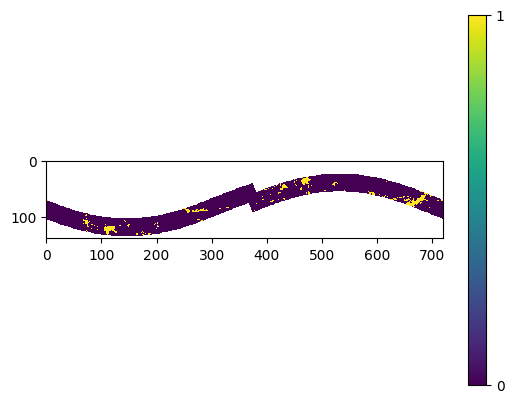

In [ ]:
masked_data = np.ma.masked_equal(predicted, -9999)

# Plotting
plt.imshow(masked_data, cmap='viridis', interpolation='nearest')

# Create colorbar
cbar = plt.colorbar()
cbar.set_ticks([0, 1])  # Set ticks for valid data (0 and 1)
cbar.set_ticklabels(['0', '1'])  # Set labels for ticks

plt.show()

In [ ]:
train_0_25={}
train_26_52={}

idx_noval=np.where(spdct['stznsp']==noval)
idx_0_25=np.where((spdct['stznsp']<26)*(spdct['stznsp']!=noval)*(spdct['bt2sp']!=noval))
idx_26_52=np.where((spdct['stznsp']>=26)*(spdct['stznsp']!=noval)*(spdct['bt2sp']!=noval))


In [ ]:
print(spdct['stznsp'][idx_0_25])

[25.82787879 25.89733333 25.83741935 ... 25.135      25.135
 25.135     ]


In [ ]:
print(np.shape(spdct['stznsp'][idx_26_52]))

(11146,)


In [ ]:
print(np.shape(spdct['stznsp'][idx_noval]))

(81797,)


In [ ]:
train_0_25['stznsp']=np.ones(np.shape(spdct['stznsp']))*noval
train_0_25['bt1sp']=np.ones(np.shape(spdct['stznsp']))*noval
train_0_25['bt2sp']=np.ones(np.shape(spdct['stznsp']))*noval
train_0_25['bt3sp']=np.ones(np.shape(spdct['stznsp']))*noval
train_0_25['bt4sp']=np.ones(np.shape(spdct['stznsp']))*noval
train_0_25['bt5sp']=np.ones(np.shape(spdct['stznsp']))*noval
train_0_25['mask']=np.ones(np.shape(spdct['stznsp']))*noval


train_0_25['stznsp']=spdct['stznsp'][idx_0_25]
train_0_25['bt1sp']=spdct['bt1sp'][idx_0_25]
train_0_25['bt2sp']=spdct['bt2sp'][idx_0_25]
train_0_25['bt3sp']=spdct['bt3sp'][idx_0_25]
train_0_25['bt4sp']=spdct['bt4sp'][idx_0_25]
train_0_25['bt5sp']=spdct['bt5sp'][idx_0_25]
train_0_25['mask']=spdct['mask'][idx_0_25]

In [ ]:
train_26_52['stznsp']=spdct['stznsp'][idx_26_52]
train_26_52['bt1sp']=spdct['bt1sp'][idx_26_52]
train_26_52['bt2sp']=spdct['bt2sp'][idx_26_52]
train_26_52['bt3sp']=spdct['bt3sp'][idx_26_52]
train_26_52['bt4sp']=spdct['bt4sp'][idx_26_52]
train_26_52['bt5sp']=spdct['bt5sp'][idx_26_52]
train_26_52['mask']=spdct['mask'][idx_26_52]

In [ ]:
test_0_25={}
test_26_52={}

test_0_25['dcc']=spdct['dcc'][idx_0_25]
test_0_25['level']=spdct['level'][idx_0_25]

test_26_52['dcc']=spdct['dcc'][idx_26_52]
test_26_52['level']=spdct['level'][idx_26_52]

In [ ]:
from sklearn.mixture import GaussianMixture






In [ ]:
features = ['stznsp', 'bt1sp', 'bt2sp', 'bt3sp', 'bt4sp', 'bt5sp', 'mask']
X_train_0_25 = np.column_stack([train_0_25[feature] for feature in features])

# Initialize and train Gaussian Mixture Model
n_components = 2 # Number of components (clusters)
gmm = GaussianMixture(n_components=n_components, covariance_type='full')
gmm.fit(X_train_0_25)

# Predict cluster assignments for the training data
train_predict_0_25 = gmm.predict(X_train_0_25)

cluster_names = [1,0]
renamed_labels_0_25= [cluster_names[label] for label in train_predict_0_25]
# Print cluster assignments for each data point
#for i, cluster in enumerate(renamed_labels_0_25):
    #print(f"Data point {i}: Cluster {cluster}")

In [ ]:
print(renamed_labels_0_25[0])

0


In [ ]:
print(idx_0_25[0][0],idx_0_25[1][0])

33 320


In [ ]:
print(len(idx_0_25[0]))

7857


In [ ]:
predicted=np.ones(np.shape(spdct['stznsp']))*noval

In [ ]:
predicted[idx_noval]=noval


In [ ]:
for i in range(len(idx_0_25)):
  for j in range(len(idx_0_25[0])):
    print(i,j)
    predicted[idx_0_25[i][j]][idx_0_25[i+1][j]]=renamed_labels_0_25[j]


In [ ]:
predicted[idx_0_25[0][0]][idx_0_25[1][0]]=renamed_labels_0_25[0]

In [ ]:
idx_0_25[1][7856]

719

In [ ]:
predicted[1][1]

-9999.0

In [ ]:
flat_idx = [(idx_0_25[0][i], idx_0_25[1][i]) for i in range(len(idx_0_25[0]))]
for (i, j), label in zip(flat_idx, renamed_labels_0_25):
    predicted[i, j] = label

In [ ]:
print(np.shape(predicted))

(140, 720)


In [ ]:
predicted

array([[-9999., -9999., -9999., ..., -9999., -9999., -9999.],
       [-9999., -9999., -9999., ..., -9999., -9999., -9999.],
       [-9999., -9999., -9999., ..., -9999., -9999., -9999.],
       ...,
       [-9999., -9999., -9999., ..., -9999., -9999., -9999.],
       [-9999., -9999., -9999., ..., -9999., -9999., -9999.],
       [-9999., -9999., -9999., ..., -9999., -9999., -9999.]])

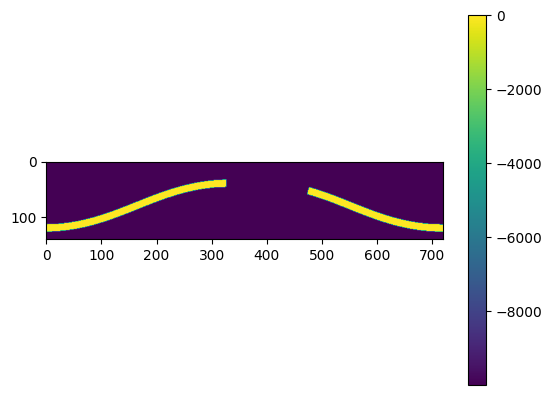

In [ ]:
plt.imshow(predicted)
plt.colorbar()
plt.show()

In [ ]:

X_train_26_52 = np.column_stack([train_26_52[feature] for feature in features])

# Initialize and train Gaussian Mixture Model
n_components = 2 # Number of components (clusters)
gmm = GaussianMixture(n_components=n_components, covariance_type='full')
gmm.fit(X_train_26_52)

# Predict cluster assignments for the training data
train_predict_26_52 = gmm.predict(X_train_26_52)

cluster_names = [1,0]
renamed_labels_26_52= [cluster_names[label] for label in train_predict_26_52]
# Print cluster assignments for each data point
#for i, cluster in enumerate(renamed_labels_26_52):
   #print(f"Data point {i}: Cluster {cluster}")

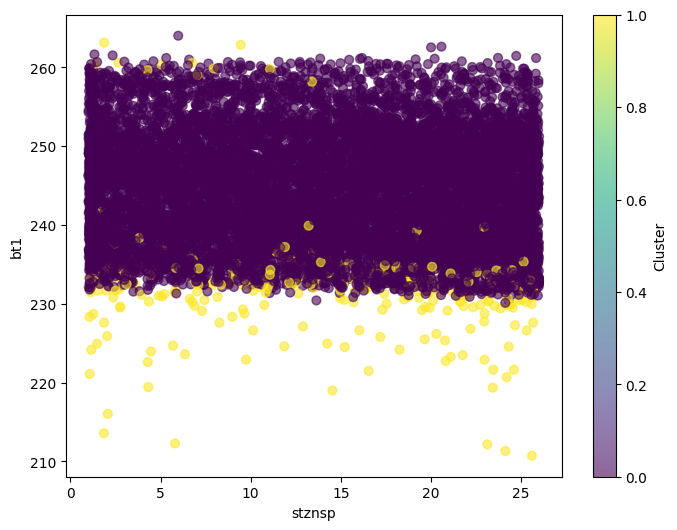

In [ ]:
import matplotlib.pyplot as plt

# Plot the clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_train_0_25[:, 0], X_train_0_25[:, 1], c=renamed_labels_0_25, cmap='viridis', s=40, alpha=0.6)
plt.colorbar(label='Cluster')
plt.title('')
plt.xlabel('stznsp')
plt.ylabel('bt1')
plt.show()

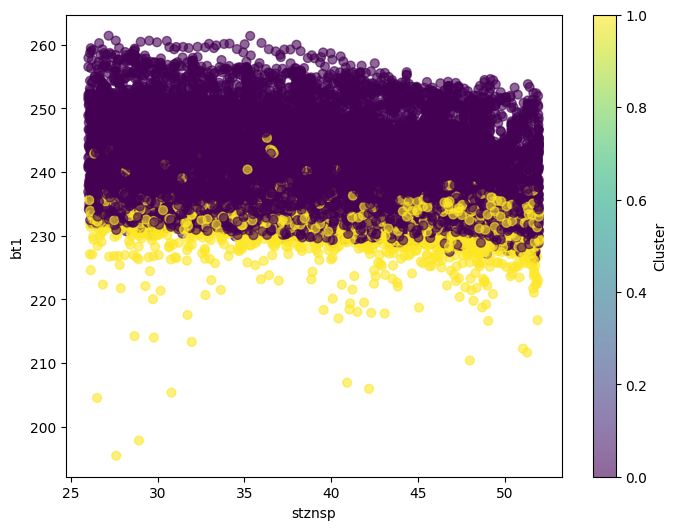

In [ ]:
# Plot the clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_train_26_52[:, 0], X_train_26_52[:, 1], c=renamed_labels_26_52, cmap='viridis', s=40, alpha=0.6)
plt.colorbar(label='Cluster')
plt.title('')
plt.xlabel('stznsp')
plt.ylabel('bt1')
plt.show()

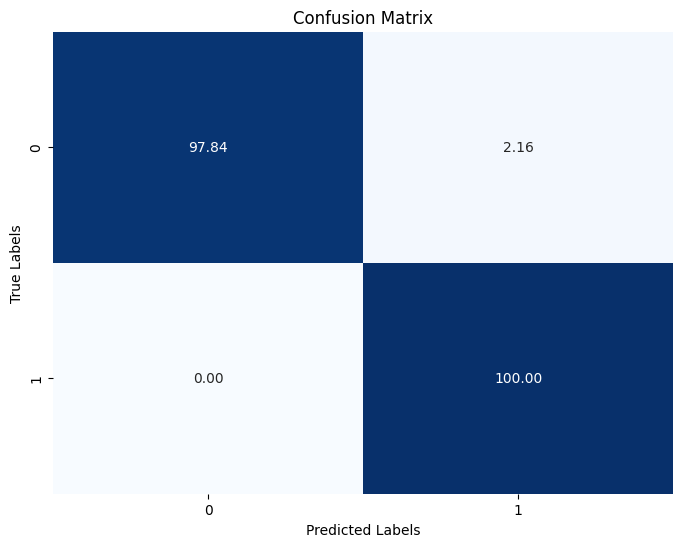

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns


# Calculate confusion matrix
cm_0_25 = confusion_matrix(test_0_25['dcc'], renamed_labels_0_25)
cm_percentage_0_25 = cm_0_25 / np.sum(cm_0_25, axis=1)[:, np.newaxis] * 100
# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_percentage_0_25, annot=True, fmt='.2f', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

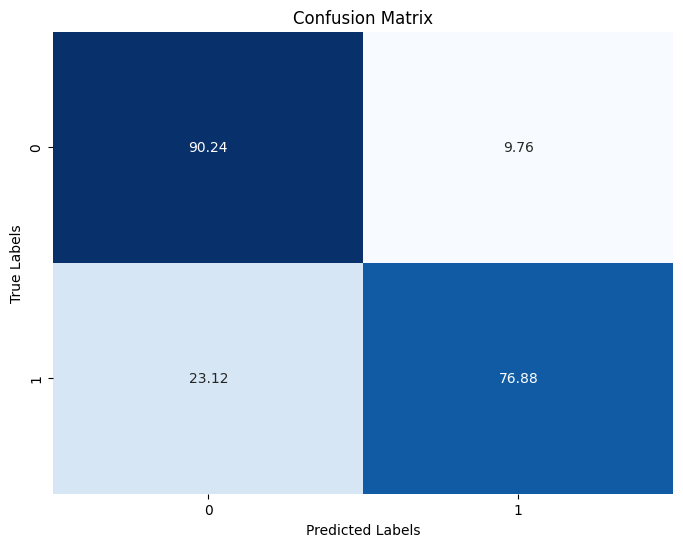

In [ ]:
# Calculate confusion matrix
cm_26_52 = confusion_matrix(test_26_52['dcc'], renamed_labels_26_52)
cm_percentage_26_52 = cm_26_52 / np.sum(cm_26_52, axis=1)[:, np.newaxis] * 100
# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_percentage_26_52, annot=True, fmt='.2f', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

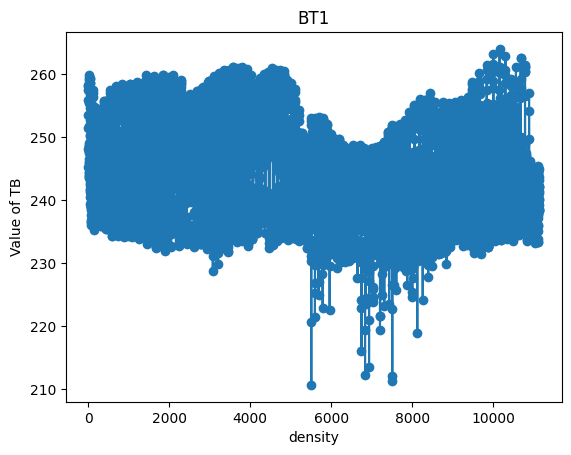

In [ ]:
plt.plot( X_train_0_25[:, 1], marker='o', linestyle='-')
plt.title("BT1")
plt.xlabel("density")
plt.ylabel("Value of TB")
plt.show()

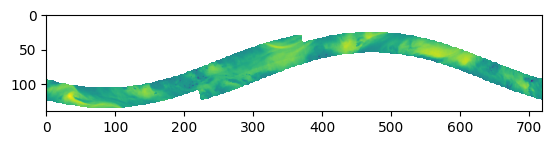

In [ ]:
bb=spdct['bt1sp']
bb[bb==noval]=np.nan
plt.imshow(bb)
plt.show()

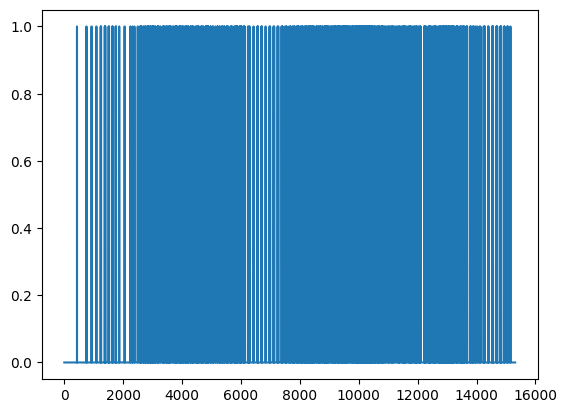

In [ ]:
plt.plot(renamed_labels_26_52)
plt.show()

In [ ]:
features = ['stznsp', 'bt1sp', 'bt2sp', 'bt3sp', 'bt4sp', 'bt5sp', 'mask']
X_train = np.column_stack([spdct[feature] for feature in features])

# Initialize and train Gaussian Mixture Model
n_components = 2 # Number of components (clusters)
gmm = GaussianMixture(n_components=n_components, covariance_type='full')
gmm.fit(X_train)

# Predict cluster assignments for the training data
train_predict_0_25 = gmm.predict(X_train)

cluster_names = [1,0]
renamed_labels_0_25= [cluster_names[label] for label in train_predict_0_25]
# Print cluster assignments for each data point
for i, cluster in enumerate(renamed_labels_0_25):
    print(f"Data point {i}: Cluster {cluster}")

ValueError: Input X contains NaN.
GaussianMixture does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values